# Exploratory Analysis of Automobile Bodily Injury Claims
**Author:** Bright Antwi

**Course:** STA 556 — Statistical Computing

**Dataset:** Automobile Bodily Injury Claims (AutoBI)

**Objective:** To investigate the distribution of economic
losses and examine their associations with attorney involvement
and claimant age.

# Part 1 — Read an external data source

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path


In [3]:
import sys

print(sys.version)

3.14.2 (main, Sep 10 2026, 12:33:04) [GCC 13.3.0]


## Reading the data using a relative path


In [4]:
ROOT = Path.cwd()

if not (ROOT / "data").exists():
    ROOT = ROOT.parent


FIGURES_DIR = ROOT / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

claims = pd.read_csv(ROOT / "data" / "AutoBi_original.csv")

Dataset: Automobile Bodily Injury Claims (AutoBI)

Source: Insurance Research Council (IRC), 2002.

The dataset contains 1,340 automobile bodily injury claims with information on claimant characteristics, attorney involvement, and economic losses. Economic loss is recorded in thousands of US dollars.

A description of the variables and coding schemes is available in 
[Data Dictionary](../data/data_dictionary.md).

Missing values are summarized in the data inspection section below.

## Inspecting the data

In [5]:
print("Dimensions:", claims.shape)

print("\nColumns:")
print(claims.columns.tolist())

print("\nIndex:")
print(claims.index)

print("\nData types:")
print(claims.dtypes)

print("\nMissing values:")
print(claims.isna().sum())

print(claims.head())
print(claims.tail())

print("\nDataset Information:")
claims.info()

Dimensions: (1340, 8)

Columns:
['CASENUM', 'ATTORNEY', 'CLMSEX', 'MARITAL', 'CLMINSUR', 'SEATBELT', 'CLMAGE', 'LOSS']

Index:
RangeIndex(start=0, stop=1340, step=1)

Data types:
CASENUM       int64
ATTORNEY      int64
CLMSEX      float64
MARITAL     float64
CLMINSUR    float64
SEATBELT    float64
CLMAGE      float64
LOSS        float64
dtype: object

Missing values:
CASENUM       0
ATTORNEY      0
CLMSEX       12
MARITAL      16
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64
   CASENUM  ATTORNEY  CLMSEX  MARITAL  CLMINSUR  SEATBELT  CLMAGE    LOSS
0        5         1     1.0      NaN       2.0       1.0    50.0  34.940
1       13         2     2.0      2.0       1.0       1.0    28.0  10.892
2       66         2     1.0      2.0       2.0       1.0     5.0   0.330
3       71         1     1.0      1.0       2.0       2.0    32.0  11.037
4       96         2     1.0      4.0       2.0       1.0    30.0   0.138
      CASENUM  ATTORNEY  CLMSEX  MARITAL  CLM

## Checking categorical codes

In [6]:
categorical_vars = [
    "ATTORNEY", "CLMSEX", "MARITAL",
    "CLMINSUR", "SEATBELT"
]

for col in categorical_vars:
    print(f"\n{col}")
    print(claims[col].value_counts(dropna=False).sort_index())


ATTORNEY
ATTORNEY
1    685
2    655
Name: count, dtype: int64

CLMSEX
CLMSEX
1.0    586
2.0    742
NaN     12
Name: count, dtype: int64

MARITAL
MARITAL
1.0    624
2.0    650
3.0     15
4.0     35
NaN     16
Name: count, dtype: int64

CLMINSUR
CLMINSUR
1.0     120
2.0    1179
NaN      41
Name: count, dtype: int64

SEATBELT
SEATBELT
1.0    1270
2.0      22
NaN      48
Name: count, dtype: int64


## Checking for duplicates and nonpositive losses

In [7]:
print("\nDuplicate case numbers:",
      claims["CASENUM"].duplicated().sum())

print("Completely duplicated rows:",
      claims.duplicated().sum())

print("Nonpositive losses:",
      (claims["LOSS"] <= 0).sum())


Duplicate case numbers: 0
Completely duplicated rows: 0
Nonpositive losses: 0


# Part 2 — Modular cleaning

In [8]:
import sys

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.cleaning import (
    recode_categories, 
    filter_complete, 
    summarize_losses,
    add_log_loss, 
    summarize_log_losses, 
    add_age_band, 
    compare_missing,
)

## Recoding the original data

In [9]:
claims_clean = recode_categories(claims)

## Summarizing losses by attorney involvement

In [10]:
attorney_summary = summarize_losses(
    claims_clean, "ATTORNEY"
)

display(attorney_summary)

,ATTORNEY,count,mean,median,std
0,No,655,1.864745,0.986,3.894149
1,Yes,685,9.863109,3.417,45.865535


## Preparing observations for the age-loss analysis

In [11]:
age_claims = filter_complete(
    claims_clean, ["CLMAGE", "LOSS"]
)

print("Total claims:", len(claims_clean))
print("Claims with recorded ages:", len(age_claims))

Total claims: 1340
Claims with recorded ages: 1151


# Part 3 — Exploratory analysis

Question 1: How do economic losses differ between attorney-represented and non-attorney-represented claims?
Question 2: What is the relationship between claimant age and economic loss?

## Descriptive statistics for claimant age and economic loss

In [12]:
age_loss_summary = age_claims[
    ["CLMAGE", "LOSS"]
].describe()

display(age_loss_summary)

,CLMAGE,LOSS
count,1151.000000,1151.000000
mean,32.530843,5.209271
std,17.088533,15.795050
min,0.000000,0.005000
25%,19.000000,0.747500
50%,31.000000,2.415000
75%,43.000000,4.125000
max,95.000000,273.604000


Interpretation of Descriptive Statistics for age:
The mean and median ages are relatively close, suggesting that the age distribution may be reasonably balanced around its center. However, we would need a histogram to assess its shape.

Note: An age of 0 could represent a child younger than one year.

# Investigating the association between age and loss (Pearson correlation and Spearman correlation)

Pearson correlation

In [13]:
pearson_corr = age_claims["CLMAGE"].corr(
    age_claims["LOSS"],
    method="pearson"
)

print(f"Pearson correlation: {pearson_corr:.4f}")

Pearson correlation: 0.0660


Spearman correlation

In [14]:
spearman_corr = age_claims["CLMAGE"].corr(
    age_claims["LOSS"],
    method="spearman"
)

print(f"Spearman correlation: {spearman_corr:.4f}")

Spearman correlation: 0.2105


Correlation interpretation:
These coefficients suggest that claimant age has very little linear association with economic loss, although there is a somewhat stronger positive association when comparing ranks.

The difference might reflect the influence of extreme claim values or a relationship that is not strictly linear. We cannot determine the explanation from correlations alone.

## Testing the influence of extreme losses using a log scale

In [15]:
claims_clean = add_log_loss(claims_clean)
age_claims = add_log_loss(age_claims)

log_summary = summarize_log_losses(claims_clean, "ATTORNEY")

display(log_summary)

,count,mean,median,std,geometric_mean,median_original
ATTORNEY,,,,,,
No,655,-0.169041,-0.014099,1.349230,0.844475,0.986
Yes,685,1.250749,1.228763,1.245717,3.492958,3.417


In [16]:
pearson_log = age_claims["CLMAGE"].corr(age_claims["LOG_LOSS"], method="pearson")

print(f"Pearson correlation (age vs. raw loss):  {pearson_corr:.4f}")
print(f"Pearson correlation (age vs. log loss):  {pearson_log:.4f}")
print(f"Spearman correlation (age vs. loss):     {spearman_corr:.4f}")

Pearson correlation (age vs. raw loss):  0.0660
Pearson correlation (age vs. log loss):  0.1831
Spearman correlation (age vs. loss):     0.2105


On the log scale, the mean and median of log loss are close within each group (no attorney: −0.169 vs. −0.014; attorney: 1.251 vs. 1.229), suggesting that the log-transformed distributions are roughly symmetric and are not dominated by extreme values. The geometric mean loss is approximately $3,493 for attorney-represented claims versus $844 for claims without an attorney, a ratio of about 4.1. This is smaller than the ratio of raw means (5.29), so a few extreme claims inflated the raw gap, but attorney-represented claims remain substantially higher, so the difference is not merely an outlier artifact. On the log scale, the spread is similar in the two groups (standard deviation 1.25 for attorney vs. 1.35 for no attorney), indicating that the large raw standard deviation among attorney-represented claims reflects a few extreme claims in the upper tail rather than greater variability overall.

The Pearson correlation between age and log loss is 0.183, compared with 0.066 on the raw scale and a Spearman correlation of 0.2105. Because the log-scale Pearson correlation is substantially higher and close to the rank correlation, extreme loss values were partly masking the association on the raw scale. Age is positively associated with loss, but the association is still weak, and correlation alone does not establish why.

## Investigating unusually large economic losses

In [17]:
loss_summary = claims_clean["LOSS"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)
display(loss_summary)


print(
    "Nonpositive losses:",
    (claims_clean["LOSS"] <= 0).sum()
)

count    1340.000000
mean        5.953461
std        33.136205
min         0.005000
25%         0.640000
50%         2.331000
75%         3.994750
90%         8.076500
95%        15.508650
99%        67.822990
max      1067.697000
Name: LOSS, dtype: float64

Nonpositive losses: 0


Descriptive analysis of economic losses:
First, the loss distribution appears highly right-skewed. The mean is more than twice the median.

Second, a small number of claims have exceptionally large losses. The maximum is over $1 million, while 99% of losses are at or below approximately $67,823.

Third, a logarithmic scale would be useful for visualization. All losses are positive, so logarithmic plots can be constructed without adjusting zero or negative values.

The descriptive analysis reveals substantial differences in economic losses according to attorney involvement. Among the 1,340 claims, 685 involved attorney representation, while 655 did not.

Attorney-represented claims had an average economic loss of approximately $9,863, compared with $1,865 for claims without attorney representation. The median losses were $3,417 and $986, respectively.

The considerably larger standard deviation among attorney-represented claims suggests greater variability in economic losses, potentially reflecting the presence of unusually large claims. Further examination of the loss distribution is necessary to investigate this possibility.

These findings indicate an association between attorney involvement and economic loss but do not establish a causal relationship.

## Missing claimant ages

## Compare losses by whether age is recorded

In [18]:
missing_age_comparison = compare_missing(claims_clean, "CLMAGE")

display(missing_age_comparison)

,Count,Mean,Median,Std,Maximum
Missing,189,10.485540,1.701,79.184916,1067.697
Recorded,1151,5.209271,2.415,15.795050,273.604


Of the 1,340 claims, 189 (14.10%) have missing claimant ages. Claims with missing ages have a higher mean economic loss ($10,485.54) than those with recorded ages ($5,209.27). However, the median loss is lower among claims with missing ages ($1,701 compared with $2,415).

This difference between the mean and median comparisons suggests that exceptionally large claims influence the average loss among observations with missing ages. In particular, the largest economic loss in the dataset belongs to a claim with missing age information.

Consequently, analyses involving claimant age are restricted to 1,151 complete observations. Because the missingness mechanism has not been established, findings from this subset should be interpreted cautiously.

## Losses by age band

In [19]:
age_banded = add_age_band(age_claims)

age_band_summary = summarize_losses(age_banded, "AGE_BAND")
display(age_band_summary)

# Median loss by age band and attorney involvement
display(
    age_banded
    .groupby(["AGE_BAND", "ATTORNEY"], observed=True)["LOSS"]
    .median()
    .unstack()
)

,AGE_BAND,count,mean,median,std
0,0-17,220,2.035532,0.869,4.557351
1,18-34,429,5.303841,2.673,15.260502
2,35-54,383,7.177517,3.132,21.159208
3,55+,119,4.400983,2.052,8.170036


ATTORNEY,No,Yes
AGE_BAND,,
0-17,0.500,1.6100
18-34,1.385,3.6320
35-54,1.300,4.0065
55+,1.030,3.3815


Median loss rises from $869 for claimants aged 0–17 to $2,673 (18–34) and $3,132 (35–54), then falls to $2,052 for those 55 and older. The relationship is hump-shaped rather than steadily increasing, which may help explain why the correlation coefficients are weak. Attorney-represented claims have a higher median loss in every age band. These are associations, not causal effects.

# Part 4 — Visualization

## Plot 1 — Distribution of economic losses

Note: Due to strong right-skewness, logarithmically spaced histogram bins are used. 

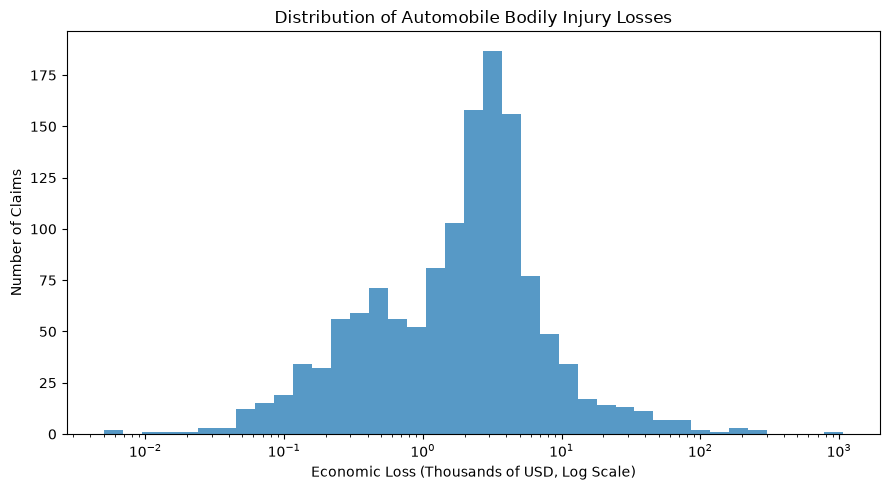

In [20]:
bins = np.logspace(
    np.log10(claims_clean["LOSS"].min()),
    np.log10(claims_clean["LOSS"].max()),
    40
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=claims_clean,
    x="LOSS",
    bins=bins,
    edgecolor="white",
    ax=ax
)

ax.set_xscale("log")

ax.set_title(
    "Distribution of Automobile Bodily Injury Losses"
)

ax.set_xlabel(
    "Economic Loss (Thousands of USD, Log Scale)"
)

ax.set_ylabel("Number of Claims")

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "loss_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Losses are strongly right-skewed: 62% of claims fall between $1,000 and $10,000, but 8 exceed $100,000 and the largest is over $1 million.

## Plot 2 — Economic losses by attorney involvement

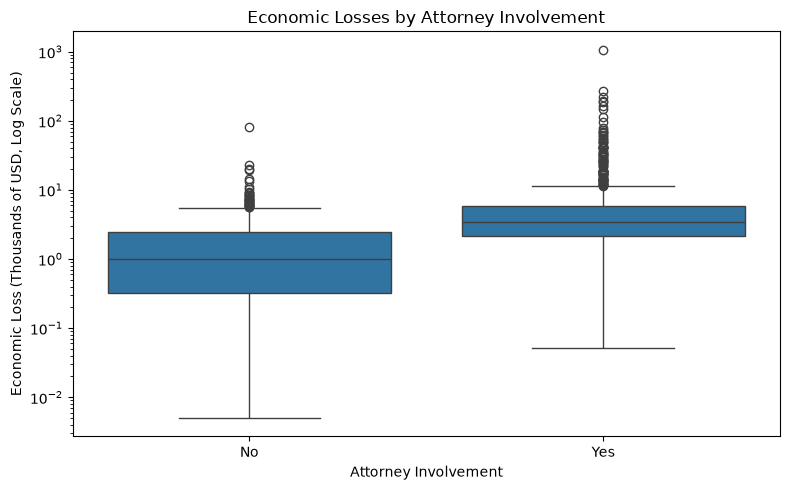

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=claims_clean,
    x="ATTORNEY",
    y="LOSS",
    order=["No", "Yes"],
    ax=ax
)

ax.set_yscale("log")

ax.set_title(
    "Economic Losses by Attorney Involvement"
)

ax.set_xlabel("Attorney Involvement")

ax.set_ylabel(
    "Economic Loss (Thousands of USD, Log Scale)"
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "loss_by_attorney.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Attorney-represented claims have a higher median loss ($3,417 vs. $986) and a much longer upper tail, though the middle 50% of the two groups overlap slightly. This shows an association, not a causal effect.

Plot 3 — Claimant age versus economic loss

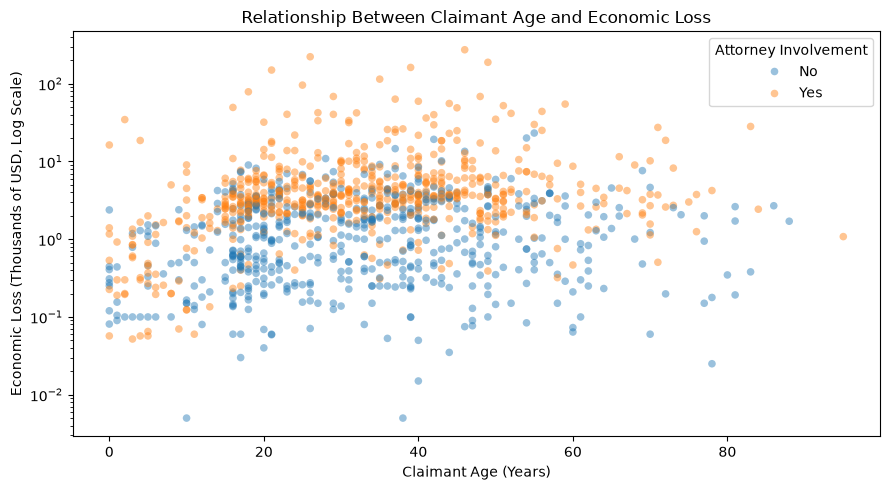

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.scatterplot(
    data=age_claims,
    x="CLMAGE",
    y="LOSS",
    hue="ATTORNEY",
    hue_order=["No", "Yes"],
    s=30,
    alpha=0.45,
    edgecolor="none",
    ax=ax
)

ax.set_yscale("log")

ax.set_title(
    "Relationship Between Claimant Age and Economic Loss"
)

ax.set_xlabel("Claimant Age (Years)")

ax.set_ylabel(
    "Economic Loss (Thousands of USD, Log Scale)"
)

ax.legend(title="Attorney Involvement")

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "age_vs_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Age and loss show only a weak positive association (Pearson 0.066, Spearman 0.210); attorney-represented claims sit higher at nearly all ages.